# INTRODUCCIÓN A LA CIENCIA DE DATOS ESPACIALES_ EVALUACIÓN 2


---

Alessandra Isabel Mendoza Tordoya - 20245523

## 1. Preparación del área de estudio

Se cargan los datos geográficos de Seattle y se preparan para realizar el análisis espacial. Para ello, se revisa la información del archivo, se unifican las zonas censales y se establece un sistema de coordenadas que permita trabajar con distancias en metros.

In [508]:
# Instalar e importar las bibliotecas necesarias
!pip install osmnx mapclassify

import geopandas as gpd
import osmnx as ox
import pandas as pd
import matplotlib.pyplot as plt
# Cargar los datos geográficos
filez = "https://github.com/Alessandra-mt/ICDE_-Ev2/raw/main/2020_Census_Tracts_Seattle_8661193084158732132.zip"
seattle = gpd.read_file(filez)
seattle.info()


<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 177 entries, 0 to 176
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   GEOID20     177 non-null    object  
 1   GROSS_ACRE  177 non-null    float64 
 2   LAND_ACRES  177 non-null    float64 
 3   WATER_ACRE  177 non-null    float64 
 4   NAME        177 non-null    object  
 5   TRACT_NUMB  177 non-null    int64   
 6   BASENAME    177 non-null    object  
 7   UVDA_AREA   177 non-null    object  
 8   CRA_NO      177 non-null    float64 
 9   CRA_GRP     177 non-null    int32   
 10  GEN_ALIAS   177 non-null    object  
 11  DETL_NAMES  177 non-null    object  
 12  C_DISTRICT  177 non-null    int64   
 13  geometry    177 non-null    geometry
dtypes: float64(4), geometry(1), int32(1), int64(2), object(6)
memory usage: 18.8+ KB


Como el archivo contiene varias zonas censales, se utiliza dissolve() para eliminar sus límites internos y obtener una geometría unificada. Después, se reproyecta al sistema EPSG:26910, adecuado para el área de Seattle y expresado en metros.

In [509]:
# Unificar las zonas censales
seattle = seattle.dissolve()
seattle = seattle[['geometry']]
# Reproyectar a coordenadas en metros
seattle = seattle.to_crs(epsg=26910)
seattle.crs

<Projected CRS: EPSG:26910>
Name: NAD83 / UTM zone 10N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: North America - between 126°W and 120°W - onshore and offshore. Canada - British Columbia; Northwest Territories; Yukon. United States (USA) - California; Oregon; Washington.
- bounds: (-126.0, 30.54, -119.99, 81.8)
Coordinate Operation:
- name: UTM zone 10N
- method: Transverse Mercator
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

La disolución reúne las zonas del archivo, pero no garantiza por sí sola que su contorno coincida exactamente con el límite administrativo de Seattle.

## 2. Descarga y preparación de las estaciones de gasolina
Se descargan las estaciones de gasolina de Seattle desde OpenStreetMap utilizando OSMnx. Posteriormente, se conservan los atributos necesarios y se organizan los registros para facilitar su identificación durante el análisis.

In [510]:
# Descargar estaciones de gasolina
stations = ox.features_from_place("Seattle, Washington, USA",tags={'amenity': 'fuel'})
stations.info()
stations.crs

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 128 entries, ('node', np.int64(457773031)) to ('way', np.int64(1460417274))
Data columns (total 73 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   geometry                   128 non-null    geometry
 1   amenity                    128 non-null    object  
 2   brand                      111 non-null    object  
 3   brand:wikidata             109 non-null    object  
 4   name                       122 non-null    object  
 5   addr:city                  47 non-null     object  
 6   addr:housenumber           51 non-null     object  
 7   addr:postcode              46 non-null     object  
 8   addr:street                51 non-null     object  
 9   check_date                 65 non-null     object  
 10  compressed_air             60 non-null     object  
 11  opening_hours              51 non-null     object  
 12  website                    49 

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

Los datos descargados presentan un índice compuesto que identifica el tipo y el código de cada elemento de OpenStreetMap. Este índice se convierte en columnas y se seleccionan el tipo de elemento, el nombre y la geometría de cada estación.

In [511]:
stations.index
# Preparar los atributos de las estaciones
stations.reset_index(drop=False, inplace=True)
stations.head()
colsToKeep = ['element', 'name', 'geometry']
fuelSeattle = stations[colsToKeep].copy()
# Reproyectar las estaciones
fuelSeattle = fuelSeattle.to_crs(seattle.crs)
fuelSeattle.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 128 entries, 0 to 127
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   element   128 non-null    object  
 1   name      122 non-null    object  
 2   geometry  128 non-null    geometry
dtypes: geometry(1), object(2)
memory usage: 3.1+ KB


Se completan los nombres faltantes con Unknown y se crea un identificador único combinando el índice del registro con su nombre. De esta manera, se evitan confusiones entre estaciones que puedan compartir una misma denominación.

In [512]:
# Crear identificadores únicos
fuelSeattle.fillna({'name': 'Unknown'}, inplace=True)
fuelSeattle['newname'] = (fuelSeattle.index.astype(str) + "_" + fuelSeattle.name)
fuelSeattle.set_index('newname', inplace=True)
fuelSeattle.drop(columns=['name'], inplace=True)
fuelSeattle.head()

,element,geometry
newname,,
0_Magnolia Chevron,node,POINT (545070.577 5276395.041)
1_76,node,POINT (551068.412 5274865.552)
2_Chevron,node,POINT (548343.649 5286720.849)
3_Shell,node,POINT (550414.847 5269839.108)
4_7-Eleven,node,POINT (550448.153 5279266.856)


# 3.Exploración de las geometrías de las estaciones
Se revisan los tipos de geometría utilizados para representar las estaciones de gasolina, ya que OpenStreetMap puede registrar un establecimiento como punto, plígono o relación. Esta revisión permitirá reconocer las diferencias que deberán considerarse en las operaciones espaciales posteriores.

In [513]:
# Identificar los tipos de geometría
pd.crosstab(fuelSeattle.element,fuelSeattle.geometry.geom_type, margins=True)

col_0,Point,Polygon,All
element,,,
node,17,0,17
way,0,111,111
All,17,111,128


## 4. Obtención y procesamiento de los centros educativos
Se descargan los centros educativos de Seattle utilizando el atributo **amenity='school'**. Los registros se procesan de manera equivalente a las estaciones de gasolina para conservar los atributos relevantes, asignar identificadores únicos y trabajar con el mismo sistema de coordenadas.

In [514]:
# Descargar los centros educativos
schools = ox.features_from_place("Seattle, Washington, USA",tags={'amenity': 'school'})
schools.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 217 entries, ('node', np.int64(356540545)) to ('way', np.int64(1547977369))
Data columns (total 74 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   geometry                 217 non-null    geometry
 1   amenity                  217 non-null    object  
 2   check_date               26 non-null     object  
 3   ele                      140 non-null    object  
 4   gnis:feature_id          146 non-null    object  
 5   name                     215 non-null    object  
 6   addr:city                158 non-null    object  
 7   addr:housenumber         166 non-null    object  
 8   addr:postcode            157 non-null    object  
 9   addr:street              166 non-null    object  
 10  opening_hours            36 non-null     object  
 11  website                  111 non-null    object  
 12  religion                 25 non-null     object  
 13  nam

Se convierte el índice original en columnas y se conservan el tipo de elemento, el nombre y la geometría de cada centro educativo. Luego, se completan los nombres faltantes y se construye un identificador único para cada registro.

In [515]:
# Preparar los atributos escolares
schools.reset_index(inplace=True)
schoolSeattle = schools[['element', 'name', 'geometry']].copy()
schoolSeattle.fillna({'name': 'Unknown'}, inplace=True)
schoolSeattle['newname'] = (schoolSeattle.index.astype(str) + "_" + schoolSeattle.name)
schoolSeattle.set_index('newname', inplace=True)
schoolSeattle.drop(columns=['name'], inplace=True)
schoolSeattle = schoolSeattle.to_crs(seattle.crs)
schoolSeattle.head()

,element,geometry
newname,,
0_Mapleleaf School,node,POINT (552925.436 5283350.335)
1_Hazel Wolf K-8,node,POINT (550876.028 5280652.219)
2_Epic Life Academy,node,POINT (549394.116 5283758.769)
3_Christ the King Elementary School,node,POINT (548515.145 5284662.849)
4_Assumption Saint Bridget School,node,POINT (553072.046 5280365.741)


Se examinan los tipos de geometría de los centros educativos mediante una tabla de frecuencias. Esta permite identificar cuántos registros corresponden a puntos, polígonos o multipolígonos.

In [516]:
# Revisar las geometrías escolares
pd.crosstab(schoolSeattle.element,schoolSeattle.geometry.geom_type,margins=True)



col_0,MultiPolygon,Point,Polygon,All
element,,,,
node,0,54,0,54
relation,4,0,2,6
way,0,0,157,157
All,4,54,159,217


A continuación, se identifican los centros educativos registrados como relaciones con geometría multipoligonal y se representan gráficamente.

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

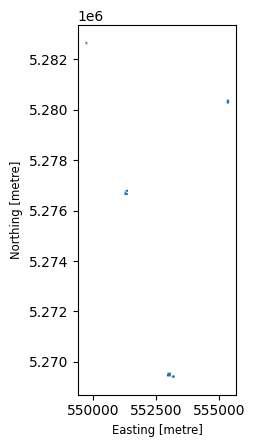

In [517]:
# Consultar las relaciones multipoligonales
schools[(schools.element == 'relation') &(schools.geometry.geom_type == 'MultiPolygon')]
# Visualizar las relaciones multipoligonales
schoolSeattle[(schoolSeattle.element == 'relation') &(schoolSeattle.geometry.geom_type == 'MultiPolygon')].plot()

Finalmente, se elabora un mapa exploratorio para observar la distribución de las estaciones de gasolina y los centros educativos dentro del área de estudio.

In [518]:
# Visualizar las estaciones y los centros educativos
base = seattle.explore(tiles='cartodbpositron',color='lightblue',style_kwds={'color': 'blue', 'weight': 2}
)
schoolSeattle.explore(m=base, color='k')
fuelSeattle.explore(m=base, color='red')
base

/usr/local/lib/python3.13/dist-packages/geopandas/explore.py:383: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(scale_factor="{r}")


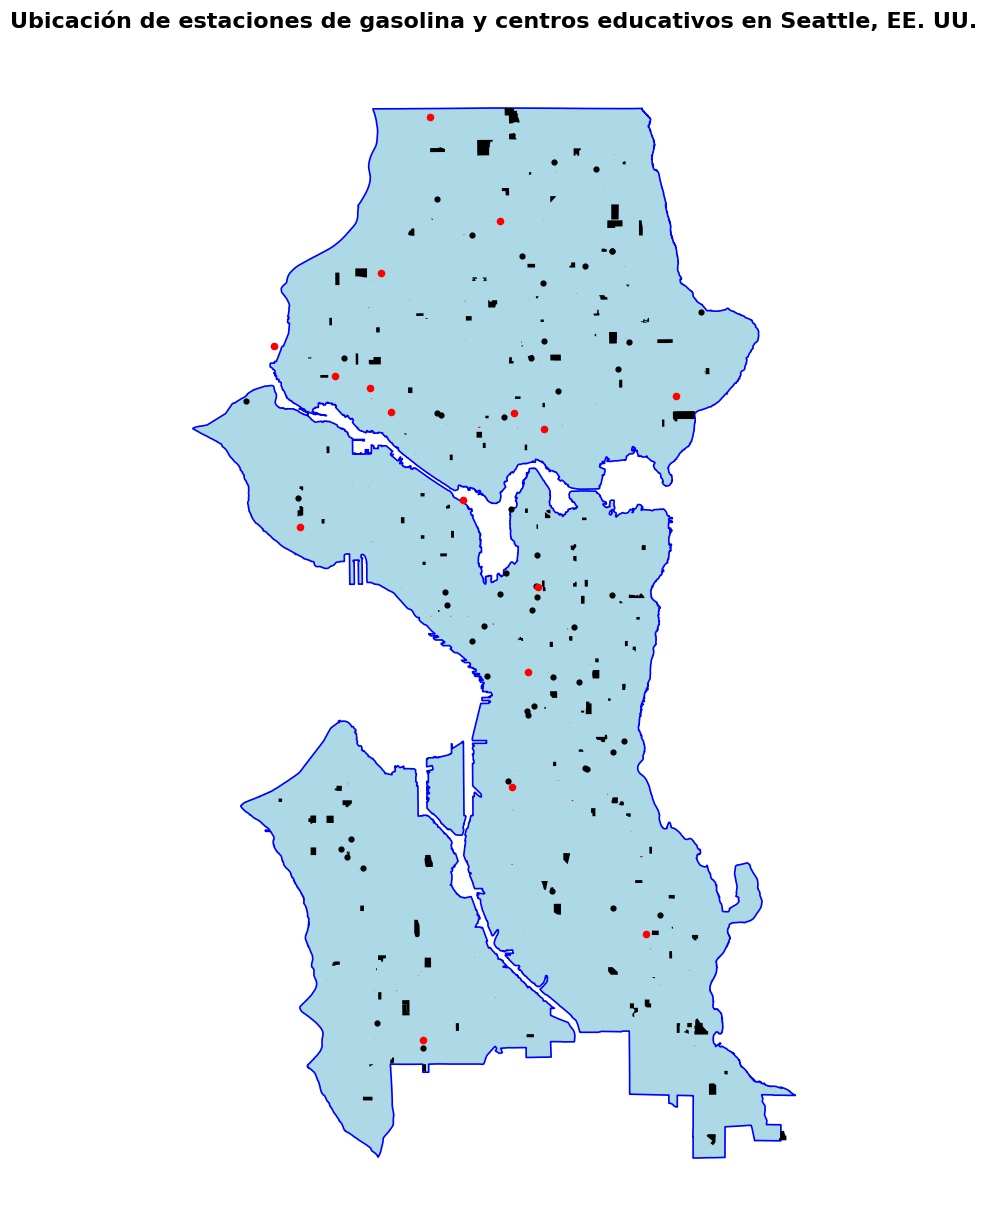

In [553]:
# Visualizar las estaciones de gasolina y los centros educativos

# Crear el mapa base de Seattle
base = seattle.plot(
    color='lightblue',
    edgecolor='blue',
    linewidth=1.2,
    figsize=(15, 15)
)
# Representar los centros educativos en negro
schoolSeattle.plot(
    ax=base,
    color='black',
    markersize=12
)
# Representar las estaciones de gasolina en rojo
fuelSeattle.plot(
    ax=base,
    color='red',
    markersize=20
)
# Agregar el título del mapa
base.set_title(
    'Ubicación de estaciones de gasolina y centros educativos en Seattle, EE. UU.',
    fontsize=16,
    fontweight='bold',
    pad=20
)
# Ajustar la presentación
base.set_aspect('equal')
base.set_axis_off()
# Mostrar un solo mapa
plt.show()

## 5. Análisis de distancias entre estaciones y centros educativos
Se calculan las distancias entre estaciones de gasolina y, posteriormente, entre estaciones y centros educativos. Estos cálculos permiten conocer su proximidad y se realizan en metros gracias al sistema de coordenadas utilizado.

In [519]:
# Distancias entre gasolineras
D_Matrix_fuel_fuel = fuelSeattle.geometry.apply(lambda station: fuelSeattle.geometry.distance(station))
D_Matrix_fuel_fuel

newname,0_Magnolia Chevron,1_76,2_Chevron,3_Shell,4_7-Eleven,5_7-Eleven,6_Morrison's North Star Marine,7_Shilshole Fuel Dock,8_Dr. Dan's Biodiesel,9_76,...,118_Chevron,119_76,120_Chevron,121_Safeway Fuel Station,122_Shell,123_Gasco & South Seattle Market,124_Shree's,125_7-Eleven,126_Unknown,127_Arco
newname,,,,,,,,,,,,,,,,,,,,,
0_Magnolia Chevron,0.000000,6189.778099,10832.142978,8458.219249,6096.362935,3911.871820,4154.629544,4607.185893,3684.919842,6799.259673,...,11032.720301,8059.083730,8471.490011,11342.071122,8388.488702,10650.766388,12839.472695,11229.479609,9704.676294,10259.885224
1_76,6189.778099,0.000000,12164.390410,5068.756372,4444.794018,7396.837510,2913.822486,9025.058016,5776.876534,2146.281615,...,10502.171854,9283.591945,5828.349523,6582.987118,3490.937461,9859.853435,10391.001557,7544.714281,5423.572544,5486.468930
2_Chevron,10832.142978,12164.390410,0.000000,17008.322965,7745.382606,6939.794167,9680.781667,6982.575734,7498.129000,14199.195661,...,3434.731016,2961.691541,7436.375075,18706.121900,15655.292108,20857.745519,22251.515513,8863.786937,17578.604974,17632.751402
3_Shell,8458.219249,5068.756372,17008.322965,0.000000,9427.806838,11287.548358,7342.660400,12635.016000,9933.327451,2922.512744,...,15557.714940,14059.287367,10879.733945,3206.070889,2163.657924,5243.026228,5325.665547,12298.163104,1528.265114,2402.851126
4_7-Eleven,6096.362935,4444.794018,7745.382606,9427.806838,0.000000,4594.203464,2537.458079,6272.831613,3095.924539,6540.437675,...,6182.494529,4939.340577,2378.849213,10960.740771,7927.629559,13808.912707,14744.043923,5152.034055,9868.081904,9889.821437
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123_Gasco & South Seattle Market,10650.766388,9859.853435,20857.745519,5243.026228,13808.912707,14330.734414,11384.887382,15256.296547,13384.622284,7840.707251,...,19975.906239,17895.800659,15622.732075,7048.807065,7406.644471,0.000000,3320.967459,17353.381510,6121.528764,6950.536820
124_Shree's,12839.472695,10391.001557,22251.515513,5325.665547,14744.043923,16185.514303,12571.965336,17343.197545,14990.551645,8245.361423,...,20883.253836,19286.809328,16183.027772,5393.694936,7165.874001,3320.967459,0.000000,17427.534449,5304.377123,5824.618469
125_7-Eleven,11229.479609,7544.714281,8863.786937,12298.163104,5152.034055,9340.534273,7314.479491,10839.148958,8108.038042,9514.437711,...,5617.194131,7342.966295,2828.590101,12564.668105,10253.850567,17353.381510,17427.534449,0.000000,12100.385190,11735.314154


Se reemplazan las distancias iguales a cero para excluir la distancia de cada estación consigo misma al consultar los valores mínimos.

In [520]:
D_Matrix_fuel_fuel.replace(0, None, inplace=True)
D_Matrix_fuel_fuel.min(axis=1).sort_values().head(10)

,0
newname,
104_ARCO,3.577986
103_ARCO,3.577986
89_76,4.467367
88_76,4.467367
30_Chevron,9.231022
11_Chevron,9.231022
91_Shell,10.521046
90_Shell,10.521046
60_Pacific Pride,12.428133


A continuación, se calculan las distancias entre las estaciones y los centros educativos.

In [521]:
# Distancias entre estaciones y colegios
D_Matrix_fuel_school = fuelSeattle.geometry.apply(lambda station: schoolSeattle.geometry.distance(station))
D_Matrix_fuel_school

newname,0_Mapleleaf School,1_Hazel Wolf K-8,2_Epic Life Academy,3_Christ the King Elementary School,4_Assumption Saint Bridget School,5_Saint Edward Parish School,6_Learning Way School,7_Concordia Lutheran School,8_Northwest Montessori School,9_Northwest Childrens Academy,...,207_Rainier Valley Leadership Academy,208_Eckstein Middle School,209_La Escuelita Bilingual School,210_Impact | Salish Sea Elementary,211_Little Laurels,212_Cascade Parent Partnership Program,213_Roxhill Elementary School,214_Downtown School,215_Seattle Waldorf School - Main Campus,216_Mercer International Middle School
newname,,,,,,,,,,,,,,,,,,,,,
0_Magnolia Chevron,10491.659688,7199.084975,8539.173303,8956.657111,8932.523151,13341.958719,13507.709663,9506.260725,4487.653030,5324.737909,...,13761.296382,9053.687052,7195.602311,14410.390399,12230.115714,3124.787461,13580.295215,4054.694024,10282.565861,10565.424327
1_76,8685.624613,5789.863861,9049.451299,10124.534305,5853.770242,8808.620825,11975.722628,6599.617370,5074.222149,880.126226,...,9194.797832,6402.592462,6089.745057,10238.137431,10878.978200,3673.708903,12398.535914,2554.619356,8612.096410,6727.699624
2_Chevron,5687.981663,6575.805111,3142.833012,2065.133147,7921.183151,20929.652730,23474.696332,7563.706626,7465.701803,11654.725826,...,21301.486962,7045.990100,6198.145060,22392.998311,4983.299678,9477.043229,23725.977819,12427.156563,5446.866035,18854.337587
3_Shell,13742.500324,10822.941478,13957.036131,14944.971496,10856.827909,4930.152593,6965.257592,11596.129786,9605.655198,5388.607746,...,5347.980500,11437.825204,11106.714608,5956.588399,15939.807496,7649.546886,7450.088356,4780.314108,13675.664902,2107.909975
4_7-Eleven,4776.163021,1449.933898,4613.922112,5731.776499,2844.708492,13184.453100,16181.746778,3413.989799,1921.307178,4045.349103,...,13557.409322,2975.949318,1688.226327,14650.612357,6843.922072,3022.474841,16531.995201,5311.494858,4626.744314,11169.644124
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123_Gasco & South Seattle Market,18437.654830,15257.637660,18016.092365,18818.447390,15701.177153,7223.804112,2917.573907,16447.522259,13440.851728,9890.137026,...,7489.956010,16219.730566,15482.629187,7043.580298,20596.596876,11308.744575,2917.011727,8493.599402,18333.769195,5192.808772
124_Shree's,19046.714482,16146.376840,19238.321146,20186.490665,16131.338043,4633.509651,2212.511637,16863.752907,14799.205507,10699.306284,...,4762.577365,16729.265591,16426.505984,3973.425033,21246.496324,12755.913237,2957.170911,9823.178035,18986.753055,3812.301432
125_7-Eleven,3191.366019,4396.077208,6402.128582,7587.141782,2308.936140,14581.418422,19250.984757,1890.496999,6978.426106,7738.111508,...,14859.036606,2191.162884,4562.774267,16156.189878,4800.640849,8052.316222,19748.085148,9560.847169,3273.765496,13416.903822


In [522]:
D_Matrix_fuel_school.min(axis=1).sort_values().head(10)

,0
newname,
102_Shell,0.824760
38_Shell,23.258460
69_Shell,36.646314
1_76,75.072216
111_Space Age,91.233431
74_Shell,94.493039
109_Shell,97.053490
96_Chevron,100.324890
36_Chevron,112.051912


## 6. Delimitación de las zonas de seguridad escolar
Se establece una distancia de seguridad de 200 metros alrededor de los centros educativos. Para ello, se generan áreas de influencia mediante buffer() y se convierten en un GeoDataFrame para utilizarlas en las operaciones espaciales.

In [523]:
# Crear zonas de seguridad escolar
mindDist = 200
schoolSeattle_buffered = schoolSeattle.buffer(mindDist)
schoolSeattle_buffered

,0
newname,
0_Mapleleaf School,"POLYGON ((553125.436 5283350.335, 553124.473 5..."
1_Hazel Wolf K-8,"POLYGON ((551076.028 5280652.219, 551075.065 5..."
2_Epic Life Academy,"POLYGON ((549594.116 5283758.769, 549593.153 5..."
3_Christ the King Elementary School,"POLYGON ((548715.145 5284662.849, 548714.182 5..."
4_Assumption Saint Bridget School,"POLYGON ((553272.046 5280365.741, 553271.083 5..."
...,...
212_Cascade Parent Partnership Program,"POLYGON ((548097.853 5277444.55, 548200.996 52..."
213_Roxhill Elementary School,"POLYGON ((547208.545 5263118.173, 547211.211 5..."
214_Downtown School,"POLYGON ((548577.36 5274495.399, 548596.968 52..."


El resultado corresponde a una GeoSeries, por lo que se consulta su tipo y posteriormente se transforma en un GeoDataFrame para utilizarlo en las siguientes operaciones espaciales.

In [524]:
# Identificar el tipo de objeto generado
type(schoolSeattle_buffered)

geopandas.geoseries.GeoSeries

In [525]:
# Convertir la GeoSeries en un GeoDataFrame
secured_schoolSeattle = gpd.GeoDataFrame(geometry=schoolSeattle_buffered)
secured_schoolSeattle

,geometry
newname,
0_Mapleleaf School,"POLYGON ((553125.436 5283350.335, 553124.473 5..."
1_Hazel Wolf K-8,"POLYGON ((551076.028 5280652.219, 551075.065 5..."
2_Epic Life Academy,"POLYGON ((549594.116 5283758.769, 549593.153 5..."
3_Christ the King Elementary School,"POLYGON ((548715.145 5284662.849, 548714.182 5..."
4_Assumption Saint Bridget School,"POLYGON ((553272.046 5280365.741, 553271.083 5..."
...,...
212_Cascade Parent Partnership Program,"POLYGON ((548097.853 5277444.55, 548200.996 52..."
213_Roxhill Elementary School,"POLYGON ((547208.545 5263118.173, 547211.211 5..."
214_Downtown School,"POLYGON ((548577.36 5274495.399, 548596.968 52..."


Finalmente, se revisan los tipos de geometría obtenidos.

In [526]:
# Revisar las geometrías de las zonas de seguridad
secured_schoolSeattle.geometry.geom_type.value_counts()

,count
Polygon,217


## 7. Identificación de las estaciones que requieren reubicación
En esta etapa, se identifican las estaciones de gasolina que se encuentran dentro de las zonas de seguridad establecidas alrededor de los centros educativos. Para realizar las operaciones espaciales, primero se revisan los tipos de geometría de las estaciones y se transforman las representaciones puntuales en superficies poligonales.

In [527]:
# Revisar las geometrías originales de las estaciones
fuelSeattle.geometry.geom_type.value_counts()

,count
Polygon,111
Point,17


Se genera una copia de las estaciones de gasolina y se aplica un buffer de 10 metros a aquellas representadas como puntos. Las estaciones que ya presentan geometrías poligonales conservan su forma original.

In [528]:
# Convertir puntos en polígonos
fuelSeattle_allPoly = fuelSeattle.copy()
fuelSeattle_allPoly['geometry'] = [
    station.buffer(10) if station.geom_type == 'Point'
    else station
    for station in fuelSeattle.geometry]
# Revisar los tipos de geometría obtenidos
fuelSeattle_allPoly.geometry.geom_type.value_counts()

,count
Polygon,128


Posteriormente, se aplica la operación **overlay()** con el método intersection para identificar las superficies donde las estaciones de gasolina coinciden espacialmente con las zonas de seguridad escolar. También se utiliza **sjoin()** para relacionar los establecimientos con las áreas que intersectan.

In [529]:
# Obtener las intersecciones entre estaciones y zonas escolares
fuelSeattle_allPoly.overlay(secured_schoolSeattle,how='intersection',keep_geom_type=False)
# Identificar las estaciones que intersectan las zonas escolares
fuelSeattle_allPoly.sjoin(secured_schoolSeattle,how='inner',predicate='intersects')

,element,geometry,newname_right
newname_left,,,
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",41_St. Nicholas School
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",152_Lowell Elementary School
3_Shell,node,"POLYGON ((550424.847 5269839.108, 550424.799 5...",18_Career Link School
5_7-Eleven,node,"POLYGON ((545961.074 5280206.532, 545961.026 5...",139_Adams Elementary School
13_Chevron,node,"POLYGON ((553783.029 5266126.575, 553782.981 5...",169_Aki Kurose Middle School
14_Gas & Smoke Depot,node,"POLYGON ((548171.175 5263445.807, 548171.127 5...",6_Learning Way School
19_Arco,way,"POLYGON ((549199.723 5283761.099, 549200.164 5...",2_Epic Life Academy
21_Safeway,way,"POLYGON ((546272.699 5269920.842, 546272.901 5...",98_Lafayette Elementary School
25_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",76_Garfield High School


El resultado de la unión espacial se almacena en un nuevo GeoDataFrame que contiene las estaciones de gasolina identificadas para su reubicación.

In [530]:
# Almacenar las estaciones que requieren reubicación
gas_relocateSeattle = fuelSeattle_allPoly.sjoin(secured_schoolSeattle,how='inner',predicate='intersects')
gas_relocateSeattle

,element,geometry,newname_right
newname_left,,,
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",41_St. Nicholas School
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",152_Lowell Elementary School
3_Shell,node,"POLYGON ((550424.847 5269839.108, 550424.799 5...",18_Career Link School
5_7-Eleven,node,"POLYGON ((545961.074 5280206.532, 545961.026 5...",139_Adams Elementary School
13_Chevron,node,"POLYGON ((553783.029 5266126.575, 553782.981 5...",169_Aki Kurose Middle School
14_Gas & Smoke Depot,node,"POLYGON ((548171.175 5263445.807, 548171.127 5...",6_Learning Way School
19_Arco,way,"POLYGON ((549199.723 5283761.099, 549200.164 5...",2_Epic Life Academy
21_Safeway,way,"POLYGON ((546272.699 5269920.842, 546272.901 5...",98_Lafayette Elementary School
25_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",76_Garfield High School


Debido a que una estación puede intersectar las zonas de seguridad de varios centros educativos, es posible que aparezcan registros repetidos. Por ello, se identifican los duplicados y se conserva un único registro por establecimiento.

In [531]:
# Identificar las estaciones con registros duplicados
is_duplicate = gas_relocateSeattle.index.duplicated(keep=False)
gas_relocateSeattle[is_duplicate]

,element,geometry,newname_right
newname_left,,,
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",41_St. Nicholas School
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",152_Lowell Elementary School
25_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",76_Garfield High School
25_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",187_Nova High School
69_Shell,way,"POLYGON ((551874.231 5273802.685, 551871.234 5...",198_Seattle World School
69_Shell,way,"POLYGON ((551874.231 5273802.685, 551871.234 5...",116_Morningside Academy
69_Shell,way,"POLYGON ((551874.231 5273802.685, 551871.234 5...",51_The Hatch School
72_7-Eleven,way,"POLYGON ((551684.055 5273748.468, 551690.484 5...",198_Seattle World School
72_7-Eleven,way,"POLYGON ((551684.055 5273748.468, 551690.484 5...",116_Morningside Academy


In [532]:
# Examinar los registros sin duplicados
gas_relocateSeattle.reset_index(drop=False).\
drop_duplicates(subset='newname_left').\
set_index('newname_left')
# Conservar un único registro por estación
gas_relocateSeattle = (
    gas_relocateSeattle.reset_index(drop=False).\
    drop_duplicates(subset='newname_left').\
    set_index('newname_left'))
gas_relocateSeattle

,element,geometry,newname_right
newname_left,,,
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",41_St. Nicholas School
3_Shell,node,"POLYGON ((550424.847 5269839.108, 550424.799 5...",18_Career Link School
5_7-Eleven,node,"POLYGON ((545961.074 5280206.532, 545961.026 5...",139_Adams Elementary School
13_Chevron,node,"POLYGON ((553783.029 5266126.575, 553782.981 5...",169_Aki Kurose Middle School
14_Gas & Smoke Depot,node,"POLYGON ((548171.175 5263445.807, 548171.127 5...",6_Learning Way School
19_Arco,way,"POLYGON ((549199.723 5283761.099, 549200.164 5...",2_Epic Life Academy
21_Safeway,way,"POLYGON ((546272.699 5269920.842, 546272.901 5...",98_Lafayette Elementary School
25_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",76_Garfield High School
34_Chevron,way,"POLYGON ((546913.57 5282556.957, 546902.092 52...",199_Whitman Middle School


Finalmente, se representa la distribución de las estaciones identificadas junto con las zonas de seguridad escolar que intersectan. Esta visualización permite reconocer espacialmente los establecimientos que requieren reubicación.

In [533]:
# Visualizar las zonas escolares y las estaciones por reubicar
base = secured_schoolSeattle.sjoin(gas_relocateSeattle,how='inner',predicate='intersects').explore(color='yellow',tiles='cartodbpositron')
gas_relocateSeattle.explore(
    m=base,
    color='red')
base

/usr/local/lib/python3.13/dist-packages/geopandas/explore.py:383: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(scale_factor="{r}")


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

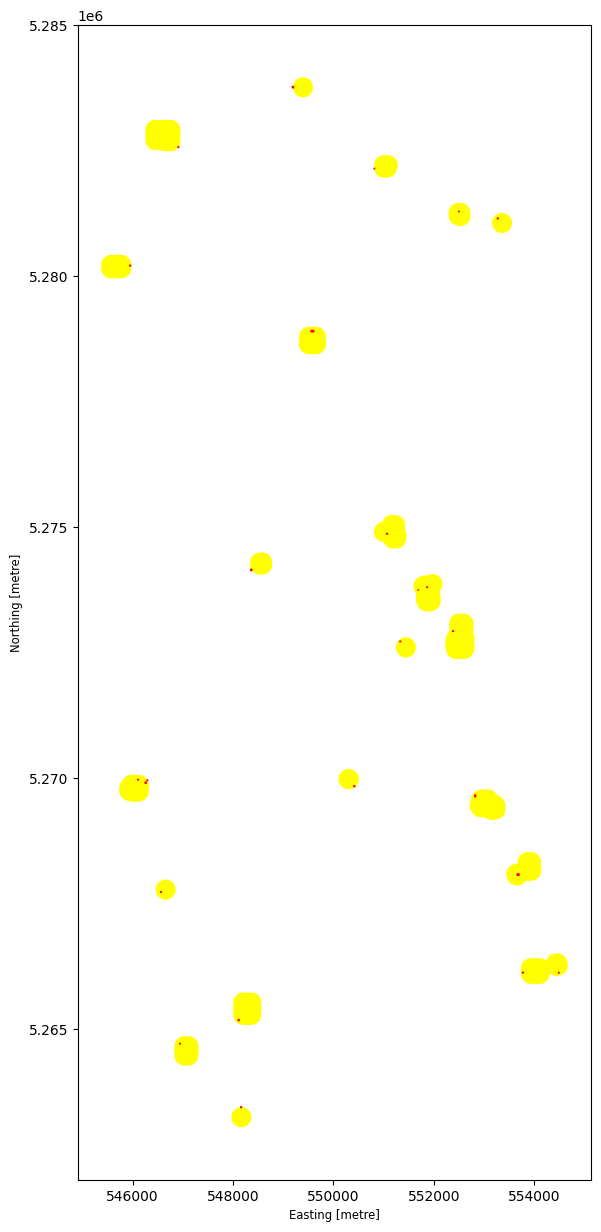

In [551]:
# En caso de que no se visualice
base = secured_schoolSeattle.sjoin(
    gas_relocateSeattle,
    how='inner',
    predicate='intersects'
).plot(color='yellow', figsize=(15, 15))

gas_relocateSeattle.plot(
    ax=base,
    facecolor='red',
    edgecolor='red'
)

## 8. Selección de carreteras adecuadas para la reubicación
En esta etapa, se identifican los tramos de la red vial de Seattle que podrían utilizarse para establecer nuevas ubicaciones de estaciones de gasolina. Para ello, se descarga la red de carreteras mediante OSMnx y se seleccionan las categorías viales consideradas en el análisis.

In [534]:
# Descargar red vial
place = "Seattle, Washington, USA"
G = ox.graph_from_place(place,network_type="drive")
# Convertir la red vial en un GeoDataFrame
streetsSeattle = ox.graph_to_gdfs(G, nodes=False, edges=True)
streetsSeattle.shape

(50301, 15)

Se examinan los atributos de la red vial y las categorías registradas en la columna **highway**, con el propósito de identificar los tipos de carretera disponibles

In [535]:
# Revisar los atributos de la red vial
streetsSeattle.info()
# Consultar las categorías de carretera
streetsSeattle.highway.value_counts().index

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 50301 entries, (np.int64(29445663), np.int64(29485641), np.int64(0)) to (np.int64(14237930653), np.int64(53073730), np.int64(0))
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   osmid     50301 non-null  object  
 1   highway   50301 non-null  object  
 2   lanes     38813 non-null  object  
 3   maxspeed  49897 non-null  object  
 4   oneway    50301 non-null  bool    
 5   ref       749 non-null    object  
 6   reversed  50301 non-null  object  
 7   length    50301 non-null  float64 
 8   geometry  50301 non-null  geometry
 9   bridge    484 non-null    object  
 10  name      44926 non-null  object  
 11  tunnel    59 non-null     object  
 12  junction  4742 non-null   object  
 13  access    237 non-null    object  
 14  width     270 non-null    object  
dtypes: bool(1), float64(1), geometry(1), object(12)
memory usage: 7.0+ MB


Index([                    'residential',                        'tertiary',
                             'secondary',                         'primary',
                          'unclassified',                   'motorway_link',
                                 'trunk',                        'motorway',
                          'primary_link',                  'secondary_link',
                         'tertiary_link',                   'living_street',
         ['residential', 'unclassified'],                      'trunk_link',
                                'busway',         ['secondary', 'tertiary'],
                ['secondary', 'primary'],  ['living_street', 'residential'],
           ['motorway', 'motorway_link'],     ['trunk_link', 'residential'],
            ['unclassified', 'tertiary'],       ['residential', 'tertiary'],
              ['trunk_link', 'tertiary'], ['residential', 'secondary_link'],
          ['tertiary', 'secondary_link'],     ['secondary', 'primary_link']]

A partir de estas categorías, se seleccionan las vías consideradas adecuadas para la localización de estaciones de gasolina, incluyendo carreteras principales y sus respectivos enlaces.

In [536]:
# Tipos de carreteras de la guía
GAS_STATION_ROAD_TYPES = [
    'motorway',
    'primary',
    'trunk',
    'motorway_link',
    'primary_link',
    'trunk_link',
    ['motorway', 'trunk'],
    ['primary', 'motorway_link'],
    ['primary', 'primary_link']
]
suitable_roadsSeattle=streetsSeattle[streetsSeattle.highway.isin(GAS_STATION_ROAD_TYPES)]
suitable_roadsSeattle.shape

(3709, 15)

Las carreteras seleccionadas se reproyectan al sistema de coordenadas del área de estudio, de manera que todas las operaciones espaciales posteriores se realicen en unidades métricas.

In [537]:
# Reproyectar las carreteras seleccionadas a EPSG:26910
suitable_roadsSeattle = suitable_roadsSeattle.to_crs(
    epsg=26910)
suitable_roadsSeattle.crs

<Projected CRS: EPSG:26910>
Name: NAD83 / UTM zone 10N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: North America - between 126°W and 120°W - onshore and offshore. Canada - British Columbia; Northwest Territories; Yukon. United States (USA) - California; Oregon; Washington.
- bounds: (-126.0, 30.54, -119.99, 81.8)
Coordinate Operation:
- name: UTM zone 10N
- method: Transverse Mercator
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

Se establece una distancia de exclusión de 100 metros alrededor de las estaciones de gasolina existentes. Mediante **buffer()**, se generan áreas de influencia que permiten considerar la proximidad entre establecimientos durante la selección de nuevas ubicaciones.

In [538]:
# Definir la distancia de exclusión entre estaciones
competitionDistance = 100
# Crear los buffers de las estaciones existentes
fuelSeattle_allPoly_buffered = fuelSeattle_allPoly.buffer(competitionDistance)
type(fuelSeattle_allPoly_buffered)

geopandas.geoseries.GeoSeries

Los buffers generados se convierten en un GeoDataFrame para integrarlos con las zonas de seguridad escolar.

In [539]:
# Convertir los buffers en un GeoDataFrame
secured_fuelSeattle_allPoly = gpd.GeoDataFrame(geometry=fuelSeattle_allPoly_buffered)

Posteriormente, se utiliza **overlay()** con la operación union para combinar las áreas de exclusión de las estaciones con las zonas de seguridad escolar. La función **dissolve()** permite unificar las superficies restringidas.

In [540]:
## Combinar las zonas de seguridad y exclusión
secured_areasSeattle_dissolved = secured_fuelSeattle_allPoly.overlay(
    secured_schoolSeattle,
    how='union',
    keep_geom_type=False
).dissolve()
# Crear el GeoDataFrame de áreas restringidas
secured_areasSeattle = gpd.GeoDataFrame(geometry=secured_areasSeattle_dissolved.geometry)

Se aplican distintas operaciones espaciales para examinar la relación entre las carreteras seleccionadas y las áreas restringidas. Primero, se utiliza **clip()** para representar los segmentos de carretera contenidos dentro de dichas áreas.

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

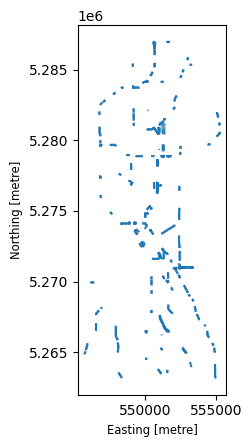

In [541]:
# Visualizar las carreteras dentro de las áreas restringidas
suitable_roadsSeattle.clip(secured_areasSeattle,keep_geom_type=False).plot()

Luego, se utiliza **overlay()** con el método difference para obtener los segmentos de carretera que se encuentran fuera de las zonas restringidas.

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

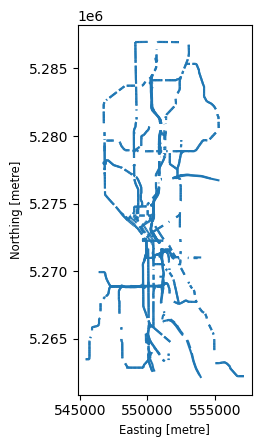

In [542]:
# Visualizar las carreteras fuera de las áreas restringidas
suitable_roadsSeattle.overlay(secured_areasSeattle,keep_geom_type=False,how='difference').plot()

Asimismo, se aplica **sjoin()** para identificar los segmentos de carretera que presentan intersecciones con las áreas de exclusión.

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

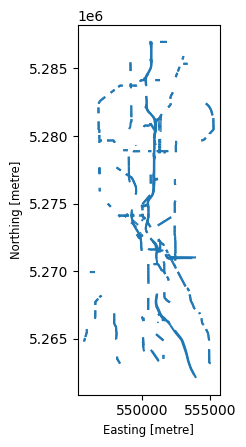

In [543]:
# Identificar las carreteras que intersectan áreas restringidas
suitable_roadsSeattle.sjoin(secured_areasSeattle,predicate='intersects').plot()

Finalmente, se utiliza la operación difference para excluir los segmentos que coinciden con las áreas restringidas. Las geometrías restantes se unifican y se almacenan como carreteras disponibles para la reubicación.

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

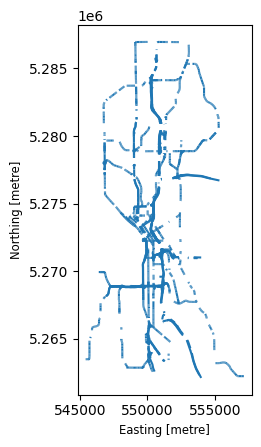

In [544]:
# Obtener las carreteras disponibles para reubicación
good_routes_forGasSeattle_dissolved = suitable_roadsSeattle.overlay(
    secured_areasSeattle,
    keep_geom_type=False,
    how='difference'
).dissolve()
# Crear el GeoDataFrame de carreteras disponibles
good_routes_forGasSeattle = gpd.GeoDataFrame(geometry=good_routes_forGasSeattle_dissolved.geometry)
# Visualizar las carreteras disponibles
good_routes_forGasSeattle.plot()

## 9. Generación de nuevas ubicaciones para las estaciones de gasolina
En esta etapa, se generan ubicaciones alternativas sobre las carreteras seleccionadas, verificando que no intersecten las áreas restringidas. Para ello, se utiliza un proceso de muestreo aleatorio y evaluación espacial.

Mediante un ciclo **while**, se generan puntos candidatos y buffers de 100 metros. El primer if comprueba que no intersecten las áreas restringidas, mientras que el segundo establece un límite de intentos.

In [545]:
# Preparar las carreteras disponibles para la reubicación
potential_LocationsSeattle = good_routes_forGasSeattle.copy()

# Inicializar las variables
newPOLYGONS_Seattle = []
pointsComputed = 1
attempts = 1
# Generar y evaluar las ubicaciones candidatas
while pointsComputed <= len(gas_relocateSeattle):
    # Generar y seleccionar un punto candidato
    sampledPoints = potential_LocationsSeattle.sample_points(2)
    candidatePoint = sampledPoints.iloc[0].geoms[0]
    # Crear un buffer de 100 metros
    candidateStation = gpd.GeoDataFrame(geometry=[candidatePoint.buffer(100)],crs=potential_LocationsSeattle.crs)
    # Verificar que no intersecte las áreas restringidas
    if candidateStation.overlay(
        secured_areasSeattle,
        how='intersection',
        keep_geom_type=False
    ).empty:
        newPOLYGONS_Seattle.append(candidateStation)
        pointsComputed += 1
        # Excluir el área seleccionada de las siguientes búsquedas
        potential_LocationsSeattle = potential_LocationsSeattle.overlay(
            candidateStation,
            how='difference',
            keep_geom_type=False
        )
    # Controlar el número máximo de intentos
    if attempts > len(gas_relocateSeattle) * 10:
        break
    attempts += 1
# Mostrar los intentos realizados y las ubicaciones aceptadas
attempts, len(newPOLYGONS_Seattle)

(34, 26)

Una vez finalizado el ciclo, se consultan las ubicaciones aceptadas y se agrupan sus geometrías mediante **pd.concat()**:

In [546]:
# Consultar las ubicaciones aceptadas
newPOLYGONS_Seattle
# Agrupar las geometrías obtenidas
pd.concat(newPOLYGONS_Seattle)

,geometry
0,"POLYGON ((552719.07 5269983.67, 552718.588 526..."
0,"POLYGON ((550786.917 5275929.613, 550786.435 5..."
0,"POLYGON ((550368.712 5283337.935, 550368.23 52..."
0,"POLYGON ((550753.664 5276084.28, 550753.183 52..."
0,"POLYGON ((551625.175 5281702.016, 551624.693 5..."
0,"POLYGON ((550511.573 5272780.096, 550511.092 5..."
0,"POLYGON ((553472.745 5263437.957, 553472.264 5..."
0,"POLYGON ((549097.383 5279267.254, 549096.901 5..."
0,"POLYGON ((551017.253 5278775.507, 551016.772 5..."
0,"POLYGON ((550362.945 5273826.346, 550362.464 5..."


Finalmente, se almacenan los buffers y se calculan sus centroides para representar las nuevas ubicaciones como puntos.

In [547]:
# Almacenar las áreas propuestas
GoodLocationsGasSeattle_buffered_gdf = pd.concat(newPOLYGONS_Seattle)
# Obtener los centroides de las propuestas
GoodLocationsGasSeattle_gdf = gpd.GeoDataFrame(geometry=GoodLocationsGasSeattle_buffered_gdf.centroid)
GoodLocationsGasSeattle_gdf

,geometry
0,POINT (552619.07 5269983.67)
0,POINT (550686.917 5275929.613)
0,POINT (550268.712 5283337.935)
0,POINT (550653.664 5276084.28)
0,POINT (551525.175 5281702.016)
0,POINT (550411.573 5272780.096)
0,POINT (553372.745 5263437.957)
0,POINT (548997.383 5279267.254)
0,POINT (550917.253 5278775.507)
0,POINT (550262.945 5273826.346)


## 10. Visualización de las propuestas y obtención de direcciones
En esta etapa, se representan las ubicaciones propuestas junto con las carreteras, centros educativos y estaciones existentes. Posteriormente, se obtienen sus direcciones aproximadas mediante geocodificación inversa.

Se utiliza **plot()** para superponer las capas geográficas, diferenciándolas mediante colores y símbolos.

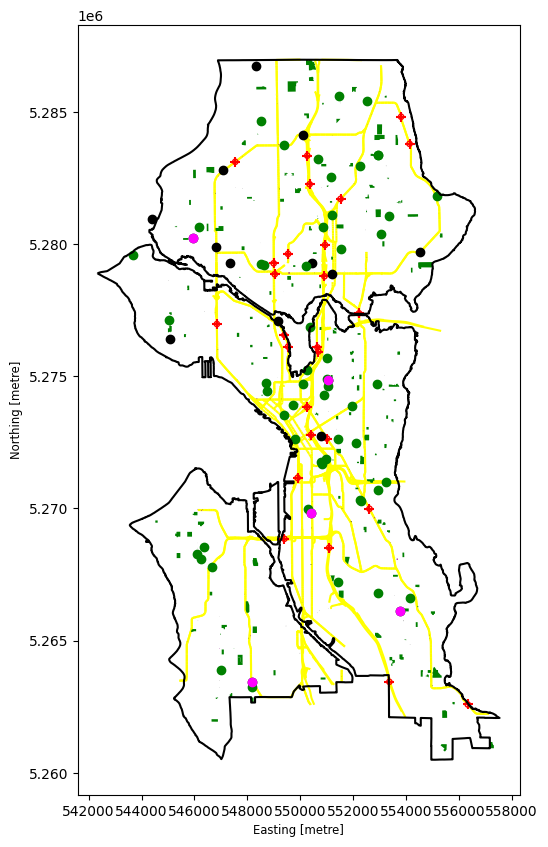

In [548]:
# Representar las carreteras seleccionadas
base = suitable_roadsSeattle.plot(
    color='yellow',
    figsize=(10, 10),
    zorder=1
)
# Representar los buffers de las propuestas
GoodLocationsGasSeattle_buffered_gdf.plot(
    ax=base,
    edgecolor='red',
    marker='+',
    facecolor='none',
    zorder=2
)
# Representar las nuevas ubicaciones
GoodLocationsGasSeattle_gdf.plot(
    ax=base,
    color='red',
    marker='+',
    markersize=50,
    zorder=3
)
# Representar las estaciones existentes
fuelSeattle.plot(ax=base, color='k', zorder=4)
# Representar los centros educativos
schoolSeattle.plot(ax=base, color='green', zorder=5)
# Destacar las estaciones que requieren reubicación
fuelSeattle.clip(gas_relocateSeattle).plot(
    ax=base,
    color='magenta',
    zorder=5
)
# Agregar el borde negro al mapa
seattle.boundary.plot(
    ax=base,
    color='black',
    linewidth=1.5,
    zorder=7
)
# Mostrar un solo mapa
plt.show()


Para identificar las direcciones, se configura Nominatim y se define una función que consulta la ubicación geográfica de cada punto.

In [549]:
# Importar las herramientas necesarias
from geopy.geocoders import Nominatim
import time
# Configurar el servicio de geocodificación
geolocator = Nominatim(user_agent="seattle_gas_stations")
# Definir la función para obtener direcciones
def get_address(point):
    lon = point.x
    lat = point.y
    location = geolocator.reverse(
        (lat, lon),
        exactly_one=True,
        timeout=10
    )
    time.sleep(1)
    return location.address if location else None

Finalmente, se transforman los puntos al sistema EPSG:4326 y se aplica la función para incorporar las direcciones obtenidas al GeoDataFrame.

In [550]:
# Transformar las ubicaciones a coordenadas geográficas
GoodLocationsGasSeattle_4326 = GoodLocationsGasSeattle_gdf.to_crs(epsg=4326)
# Obtener las direcciones aproximadas
GoodLocationsGasSeattle_gdf['address'] = (GoodLocationsGasSeattle_4326.geometry.apply(get_address))
# Consultar los resultados finales
GoodLocationsGasSeattle_gdf

,geometry,address
0,POINT (552619.07 5269983.67),"2505, Rainier Avenue South, Beacon Hill, Seatt..."
0,POINT (550686.917 5275929.613),"F45 Training, 1800, Eastlake Avenue East, East..."
0,POINT (550268.712 5283337.935),"I 5 Express, Licton Springs, Northgate, Seattl..."
0,POINT (550653.664 5276084.28),"1901, Eastlake Avenue East, Eastlake, Cascade,..."
0,POINT (551525.175 5281702.016),"Lake City Way Northeast, Green Lake, Seattle, ..."
0,POINT (550411.573 5272780.096),"I 5 Express, Central Business District, First ..."
0,POINT (553372.745 5263437.957),"I 5, South Beacon Hill, Seattle, King County, ..."
0,POINT (548997.383 5279267.254),"Aurora Avenue North, Phinney Ridge, Seattle, K..."
0,POINT (550917.253 5278775.507),"I 5, West Campus, University Heights, Universi..."
0,POINT (550262.945 5273826.346),"1759, Boren Avenue, First Hill, Seattle, King ..."
